# RuBERT-tiny2: текстовое базовое решение B

**Выполнено на CPU 2026-10-18: два обучения и девять сравнений.**
Повторный Run All создаёт новый опыт; прежние результаты сохраняются.
Два независимых классификатора, по одному на цель. Единственный вход —
исходный operator_log. Диагноз не зависит от решения модели отказа.
required_route, severity, id и цели не передаются в кодировщик.

Фиксированная настройка: полное обучение кодировщика и новой
классификационной части, learning_rate=0.00005, пять эпох, batch=32,
max_length=128, seed=42. Поиска гиперпараметров нет: **два обучения**.
Все эпохи выполняются; лучшая выбирается по validation AP или macro-F1.
Равенство до 12 знаков разрешается в пользу более ранней эпохи.

Разбиение eda_v1 неизменно. Test не оценивается. Повторяемость шести
шаблонов ограничивает выводы о новых формулировках. Улучшение относительно
TF-IDF — гипотеза. Один seed не характеризует вариативность обучения.
Исполнитель реализации — агент по согласованному решению пользователя;
авторство других участников этим не устанавливается.

## Окружение и устройство

В следующей ячейке задайте `DEVICE = "cpu"` (локально) или `"cuda"` (NVIDIA). Затем Restart Kernel → Run All. Рабочий каталог — notebooks/experiments; ядро — .venv Python 3.11. CUDA проверяется до загрузки данных; скрытого перехода на CPU нет. Если видны несколько GPU, заранее задайте CUDA_VISIBLE_DEVICES. Оба режима используют один протокол FP32 и два обучения.


In [1]:
import hashlib
import json
import logging
import os
import platform
import shutil
import sys
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
PROJECT_ROOT = Path("../..").resolve()
if not (PROJECT_ROOT / "configs/04_rubert_tiny2.json").is_file():
    raise RuntimeError("Рабочий каталог должен быть notebooks/experiments.")
if Path(sys.prefix).resolve() != (PROJECT_ROOT / ".venv").resolve():
    raise RuntimeError("Выберите ядро .venv проекта.")
if sys.version_info[:2] != (3, 11):
    raise RuntimeError("Нужен Python 3.11.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.environ.setdefault("HF_HOME", str(PROJECT_ROOT / ".cache/huggingface"))

'C:\\Users\\Mo\\work\\study\\Магистратура\\2к\\1с\\LLMs\\.cache\\huggingface'

In [2]:
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
    confusion_matrix,
)
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

from industrial_maintenance import baseline, data, text_transformer
from industrial_maintenance.comparison import paired_group_bootstrap

DEVICE = "cpu"  # На сервере замените на "cuda" перед Run All.

CONFIG = json.loads(
    (PROJECT_ROOT / "configs/04_rubert_tiny2.json").read_text(encoding="utf-8")
)
CONFIG["execution"]["device"] = DEVICE
hardware = text_transformer.configure_execution(
    DEVICE, CONFIG["execution"]["cpu_threads"]
)
display(hardware)
assert CONFIG["features"] == ["operator_log"]
assert CONFIG["expected_training_runs"] == len(CONFIG["targets"]) == 2
versions = {
    name: version(name)
    for name in [
        "torch", "transformers", "accelerate", "numpy", "pandas",
        "scikit-learn", "mlflow", "scipy",
    ]
}
display(CONFIG)
display(pd.Series(versions, name="Версия"))

C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/10/18 14:16:19 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


{'device': 'cpu',
 'cpu_threads': 6,
 'logical_cpus': 12,
 'cuda_build': None,
 'gpu': None,
 'gpu_bytes': None}

{'model_id': 'cointegrated/rubert-tiny2',
 'notebook': 'notebooks/experiments/04_rubert_tiny2.ipynb',
 'revision': 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae',
 'features': ['operator_log'],
 'excluded_features': ['required_route',
  'severity',
  'id',
  'failure_within_30d',
  'fault_type'],
 'dataset_config': 'configs/eda_16_10.json',
 'membership_file': 'Data/splits/eda_v1/membership.csv',
 'split_manifest': 'Data/splits/eda_v1/manifest.json',
 'membership_sha256': '7df958804864a5e37776843f66ab7ab358b74a685188df14f60eb83cddea00b1',
 'expected_sizes': {'train': 10655, 'validation': 2193, 'test': 2152},
 'targets': {'failure_within_30d': 'average_precision',
  'fault_type': 'macro_f1'},
 'expected_classes': {'failure_within_30d': [0, 1],
  'fault_type': ['bearing_wear',
   'cavitation',
   'imbalance',
   'normal',
   'overheat',
   'seal_leak']},
 'expected_training_runs': 2,
 'max_length': 128,
 'seed': 42,
 'execution': {'device': 'cpu', 'cpu_threads': 6},
 'training': {'learning_r

torch            2.9.1
transformers    4.57.6
accelerate      1.12.0
numpy            2.4.6
pandas           3.0.6
scikit-learn     1.9.1
mlflow          3.17.1
scipy           1.17.1
Name: Версия, dtype: str

## 2. Неизменяемые данные и только train/validation

Полный CSV читается для проверки контрольной суммы и разбиения.
После проверки test не передаётся ни в токенизацию, ни в обучение,
ни в оценивание. Исходные журналы не очищаются и не маскируются.

In [3]:
dataset_config = json.loads(
    (PROJECT_ROOT / CONFIG["dataset_config"]).read_text(encoding="utf-8")
)
frame, source_manifest = data.load_dataset(PROJECT_ROOT, dataset_config)
membership_path = PROJECT_ROOT / CONFIG["membership_file"]
assert data.file_sha256(membership_path) == CONFIG["membership_sha256"]
split_manifest = json.loads(
    (PROJECT_ROOT / CONFIG["split_manifest"]).read_text(encoding="utf-8")
)
assert split_manifest["protocol"]["sha256"] == source_manifest["sha256"]
assert split_manifest["membership_sha256"] == CONFIG["membership_sha256"]
assert split_manifest["sizes"] == CONFIG["expected_sizes"]
membership = pd.read_csv(membership_path, dtype={"id": "string"})
data.validate_splits(frame, membership)
parts = {}
for split in ["train", "validation"]:
    ids = membership.loc[membership["split"].eq(split), "id"]
    parts[split] = frame.loc[frame["id"].isin(ids)].copy()
    assert len(parts[split]) == CONFIG["expected_sizes"][split]
del frame
train, validation = parts["train"], parts["validation"]
for target, expected_classes in CONFIG["expected_classes"].items():
    assert sorted(train[target].unique().tolist()) == expected_classes
    assert set(validation[target]).issubset(set(expected_classes))
    display(pd.DataFrame({
        "train": train[target].value_counts(),
        "validation": validation[target].value_counts(),
    }))
display(pd.Series(split_manifest["sizes"], name="Размер выборки"))

,train,validation
failure_within_30d,,
0,8870,1830
1,1785,363


,train,validation
fault_type,,
bearing_wear,1261,255
cavitation,1069,222
imbalance,1147,232
normal,4783,1005
overheat,1215,252
seal_leak,1180,227


train         10655
validation     2193
test           2152
Name: Размер выборки, dtype: int64

## 3. Закреплённые контроли и соответствие id

Читаем TF-IDF, числовой CatBoost и prior из явно указанных запусков.
Модели не переобучаются, их файлы и MLflow не изменяются.
TF-IDF имеет те же входы; CatBoost получает другую информацию.

In [4]:
references = {}
reference_checksums = {}
for reference in CONFIG["references"]:
    batch = PROJECT_ROOT / reference["batch"]
    reference_manifest = json.loads(
        (batch / "manifest.json").read_text(encoding="utf-8")
    )
    assert reference_manifest["status"] == "completed"
    assert not reference_manifest["test_evaluated"]
    assert reference_manifest["source"]["sha256"] == source_manifest["sha256"]
    assert (
        reference_manifest["config"]["membership_sha256"]
        == CONFIG["membership_sha256"]
    )
    assert reference_manifest["split"]["sizes"] == split_manifest["sizes"]
    selected = pd.read_csv(batch / reference["table"])
    selected = selected.loc[selected["variant"].eq(reference["variant"])]
    assert len(selected) == 2
    paths = [batch / "manifest.json", batch / reference["table"]]
    for row in selected.to_dict("records"):
        target = row["target"]
        directory = PROJECT_ROOT / row["run_path"]
        trial = json.loads(
            (directory / "manifest.json").read_text(encoding="utf-8")
        )
        assert sorted(trial["classes"]) == CONFIG["expected_classes"][target]
        assert not set(CONFIG["excluded_features"]).intersection(
            trial["features"]
        )
        predictions = pd.read_csv(
            directory / "validation_predictions.csv",
            dtype={"id": "string"}, float_precision="round_trip",
        )
        truth = validation.set_index("id")[target]
        assert predictions.id.is_unique
        assert set(predictions.id) == set(truth.index)
        np.testing.assert_array_equal(
            predictions.set_index("id").loc[truth.index, "y_true"], truth
        )
        references[(reference["name"], target)] = {
            "predictions": predictions, "directory": directory,
        }
        paths.extend([
            directory / "manifest.json",
            directory / "validation_predictions.csv",
        ])
        if target == "failure_within_30d":
            paths.append(directory / "validation_predictions_f2.csv")
    for path in paths:
        reference_checksums[path.relative_to(PROJECT_ROOT).as_posix()] = (
            data.file_sha256(path)
        )
display(pd.DataFrame([
    {"control": name, "target": target, **baseline.classification_metrics(
        item["predictions"], CONFIG["expected_classes"][target], target
    )}
    for (name, target), item in references.items()
]))

,control,target,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision
0,tfidf,failure_within_30d,0.832649,0.500820,0.313482,0.452381,0.052342,0.093827,0.063588,0.855282,0.442193
1,tfidf,fault_type,1.000000,1.000000,0.043574,NaN,NaN,NaN,NaN,NaN,NaN
2,catboost_numeric,failure_within_30d,0.892841,0.795255,0.203937,0.702532,0.611570,0.653903,0.627828,0.948259,0.786742
3,catboost_numeric,fault_type,0.807570,0.757161,0.461973,NaN,NaN,NaN,NaN,NaN,NaN
4,prior,failure_within_30d,0.834473,0.454884,0.448736,0.000000,0.000000,0.000000,0.000000,0.500000,0.165527
5,prior,fault_type,0.458276,0.104753,1.561055,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Готовый токенизатор и длина последовательности

Словарь не обучается на наших данных. Ограничение 128 проверяем на train;
если оно обрезает тексты, эксперимент останавливается для явного решения.
Длина validation сохраняется как диагностика без изменения настройки.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(
    CONFIG["model_id"], revision=CONFIG["revision"], trust_remote_code=False
)
length_records = []
for split, part in parts.items():
    texts = text_transformer.text_inputs(part[CONFIG["features"]])
    tokens = tokenizer(texts, truncation=False, padding=False)
    lengths = np.array([len(sequence) for sequence in tokens["input_ids"]])
    length_records.append({
        "split": split, "rows": len(lengths),
        "max_tokens": int(lengths.max()),
        "mean_tokens": float(lengths.mean()),
        "truncated_rows": int((lengths > CONFIG["max_length"]).sum()),
    })
    if split == "train" and (lengths > CONFIG["max_length"]).any():
        raise ValueError(
            "max_length обрезает train; сначала уточните настройку."
        )
token_lengths = pd.DataFrame(length_records)
display(token_lengths)

,split,rows,max_tokens,mean_tokens,truncated_rows
0,train,10655,20,18.206851,0
1,validation,2193,20,18.186047,0


## 5. Устройство, новый каталог и исходный код

CPU или CUDA уже проверены в начале тетради. Каждый запуск создаёт
новый каталог и сохраняет все эпохи для восстановления. Режим CPU
использует шесть потоков; CUDA — один видимый NVIDIA GPU.
Автоматических повторов или возобновлений нет. Инструкция переноса:
../../TRANSFORMER_SERVER.md.


In [6]:
started = datetime.now(timezone.utc)
batch_id = CONFIG["batch_prefix"] + started.strftime("%Y%m%dT%H%M%S_%fZ")
batch_directory = PROJECT_ROOT / CONFIG["output_root"] / batch_id
batch_directory.mkdir(parents=True, exist_ok=False)


def write_json(path, value):
    """Сохранить JSON в UTF-8 без нечисловых значений NaN."""
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )


logger = logging.getLogger(CONFIG["experiment_name"])
for handler in list(logger.handlers):
    handler.close()
    logger.removeHandler(handler)
logger.setLevel(logging.INFO)
logger.propagate = False
for handler in [
    logging.StreamHandler(sys.stdout),
    logging.FileHandler(batch_directory / "run.log", encoding="utf-8"),
]:
    handler.setFormatter(logging.Formatter("%(asctime)s %(message)s"))
    logger.addHandler(handler)
hardware.update({"platform": platform.platform(), "python": sys.version})
source_directory = batch_directory / "source"
source_directory.mkdir()
source_checksums = {}
for relative in [*CONFIG["source_files"], "pyproject.toml", "uv.lock"]:
    path = PROJECT_ROOT / relative
    destination = source_directory / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(path, destination)
    source_checksums[relative] = data.file_sha256(path)
notebook = json.loads(
    (PROJECT_ROOT / CONFIG["notebook"]).read_text(encoding="utf-8")
)
notebook_code = "\n\n".join(
    "".join(cell["source"])
    for cell in notebook["cells"] if cell["cell_type"] == "code"
)
(source_directory / "notebook_code.py").write_text(
    notebook_code, encoding="utf-8"
)
manifest = {
    "status": "running", "batch_id": batch_id, "config": CONFIG,
    "source": source_manifest, "split": split_manifest,
    "libraries": versions, "hardware": hardware,
    "source_checksums": source_checksums,
    "notebook_code_sha256": hashlib.sha256(
        notebook_code.encode("utf-8")
    ).hexdigest(),
    "reference_checksums": reference_checksums,
    "started_at_utc": started.isoformat(),
    "test_evaluated": False,
    "completed_training_runs": 0,
}
write_json(batch_directory / "manifest.json", manifest)
write_json(batch_directory / "config.json", CONFIG)
token_lengths.to_csv(batch_directory / "token_lengths.csv", index=False)
tracking_database = PROJECT_ROOT / CONFIG["tracking_database"]
tracking_database.parent.mkdir(parents=True, exist_ok=True)
tracking_artifacts = PROJECT_ROOT / CONFIG["tracking_artifacts"]
tracking_artifacts.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri("sqlite:///" + tracking_database.as_posix())
experiment = mlflow.get_experiment_by_name(CONFIG["experiment_name"])
experiment_id = (
    experiment.experiment_id if experiment else mlflow.create_experiment(
        CONFIG["experiment_name"],
        artifact_location=tracking_artifacts.as_uri(),
    )
)
logger.info("Начало %s; два обучения; %s", batch_id, hardware["device"])

2026/10/18 14:16:27 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/18 14:16:27 INFO mlflow.store.db.utils: Updating database tables


2026-10-18 14:16:29,828 Начало rubert_tiny2_20261018T111625_114468Z; два обучения; cpu


## 6. Два независимых обучения и выбор эпохи

Каждая модель заново загружает исходные веса. Cross-entropy без весов
классов, AdamW и линейное расписание заданы конфигурацией. Encoder
полностью обучаемый. Validation используется только для оценки эпох.
Сохраняем checkpoints, журнал потерь, предупреждения и выбранную модель.
Один MLflow run на цель; оценивание и порог новых run не создают.

In [7]:
results = []
prediction_tables = {}
reloaded_predictions = {}
for target, primary_metric in CONFIG["targets"].items():
    classes = CONFIG["expected_classes"][target]
    set_seed(CONFIG["seed"])
    datasets = {
        split: text_transformer.TextDataset(
            part[CONFIG["features"]], part[target], classes,
            tokenizer, CONFIG["max_length"],
        )
        for split, part in parts.items()
    }

    def evaluate_epoch(output):
        """Рассчитать метрики эпохи на неизменной validation."""
        # 1) Сопоставить выходы и исходные метки в порядке validation.
        predictions = text_transformer.predictions_from_logits(
            validation.id, validation[target], output.predictions,
            classes, target, CONFIG["binary_threshold"],
        )
        # 2) Использовать те же определения метрик, что и у контролей.
        return baseline.classification_metrics(predictions, classes, target)

    with mlflow.start_run(
        experiment_id=experiment_id, run_name=batch_id + "_" + target,
        tags={"batch_id": batch_id, "target": target, "system": "B"},
    ) as active_run:
        run_id = active_run.info.run_id
        directory = batch_directory / "runs" / run_id
        directory.mkdir(parents=True)
        trial = {
            **manifest, "status": "running", "target": target,
            "classes": classes, "features": CONFIG["features"],
            "run_id": run_id,
        }
        write_json(directory / "manifest.json", trial)
        write_json(directory / "config.json", CONFIG)
        clock = perf_counter()
        try:
            with warnings.catch_warnings(record=True) as recorded_warnings:
                warnings.simplefilter("always")
                model = text_transformer.build_text_classifier(
                    CONFIG["model_id"], CONFIG["revision"], classes
                )
                assert all(
                    parameter.requires_grad for parameter in model.parameters()
                )
                trainable_parameters = sum(
                    parameter.numel() for parameter in model.parameters()
                )
                arguments = TrainingArguments(
                    output_dir=str(directory / "checkpoints"),
                    seed=CONFIG["seed"], data_seed=CONFIG["seed"],
                    disable_tqdm=True, use_cpu=(DEVICE == "cpu"),
                    **CONFIG["training"],
                )
                trainer = Trainer(
                    model=model, args=arguments,
                    train_dataset=datasets["train"],
                    eval_dataset=datasets["validation"],
                    processing_class=tokenizer,
                    data_collator=DataCollatorWithPadding(tokenizer),
                    compute_metrics=evaluate_epoch,
                )
                logger.info("Обучение %s, MLflow %s", target, run_id)
                clock = perf_counter()
                trainer.train()
                fit_seconds = perf_counter() - clock
                history = trainer.state.log_history
                write_json(directory / "training_summary.json", {
                    "fit_seconds": fit_seconds, "history": history,
                })
                best = text_transformer.select_epoch(
                    history, primary_metric, CONFIG["selection_decimals"]
                )
                best_checkpoint = directory / "checkpoints" / (
                    "checkpoint-" + str(best["step"])
                )
                del trainer, model
                if DEVICE == "cuda":
                    torch.cuda.empty_cache()
                model = AutoModelForSequenceClassification.from_pretrained(
                    best_checkpoint, use_safetensors=True,
                    attn_implementation="eager",
                )
                model.save_pretrained(directory / "model")
                tokenizer.save_pretrained(directory / "model")
                trainer = text_transformer.build_prediction_trainer(
                    model, arguments, tokenizer
                )
                metrics = {}
                for split, part in parts.items():
                    inference_clock = perf_counter()
                    logits = trainer.predict(datasets[split]).predictions
                    predictions = text_transformer.predictions_from_logits(
                        part.id, part[target], logits, classes, target,
                        CONFIG["binary_threshold"],
                    )
                    assert predictions.id.tolist() == part.id.tolist()
                    prediction_tables[(target, split)] = predictions
                    predictions.to_csv(
                        directory / f"{split}_predictions.csv", index=False
                    )
                    metrics[split] = baseline.classification_metrics(
                        predictions, classes, target
                    )
                    metrics[split]["prediction_seconds"] = (
                        perf_counter() - inference_clock
                    )
                restored = AutoModelForSequenceClassification.from_pretrained(
                    directory / "model", attn_implementation="eager"
                )
                del trainer, model
                if DEVICE == "cuda":
                    torch.cuda.empty_cache()
                restored_trainer = text_transformer.build_prediction_trainer(
                    restored, arguments, tokenizer
                )
                reloaded = text_transformer.predictions_from_logits(
                    validation.id, validation[target],
                    restored_trainer.predict(datasets["validation"]).predictions,
                    classes, target, CONFIG["binary_threshold"],
                )
                columns = [f"probability_{label}" for label in classes]
                np.testing.assert_allclose(
                    reloaded[columns],
                    prediction_tables[(target, "validation")][columns],
                    rtol=1e-6, atol=1e-7,
                )
                np.testing.assert_array_equal(
                    reloaded.y_pred,
                    prediction_tables[(target, "validation")].y_pred,
                )
                reloaded_predictions[target] = reloaded
                del restored_trainer, restored
                if DEVICE == "cuda":
                    torch.cuda.empty_cache()
            warning_text = "\n".join(
                str(item.message) for item in recorded_warnings
            )
            (directory / "warnings.log").write_text(
                warning_text, encoding="utf-8"
            )
            write_json(directory / "history.json", history)
            write_json(directory / "metrics.json", metrics)
            trial.update({
                "status": "completed", "best_epoch": best,
                "fit_seconds": fit_seconds, "reload_verified": True,
                "trainable_parameters": trainable_parameters,
            })
            write_json(directory / "manifest.json", trial)
            mlflow.log_params({
                "model_id": CONFIG["model_id"], "revision": CONFIG["revision"],
                "target": target, "features": "operator_log",
                "seed": CONFIG["seed"], **CONFIG["execution"],
                **CONFIG["training"],
            })
            mlflow.log_metrics({
                f"{split}_{name}": value
                for split, values in metrics.items()
                for name, value in values.items() if value is not None
            })
            mlflow.log_metric("fit_seconds", fit_seconds)
            for row in history:
                mlflow.log_metrics({
                    key: float(value) for key, value in row.items()
                    if isinstance(value, (int, float)) and key != "step"
                }, step=int(row["step"]))
            for path in directory.glob("*.*"):
                mlflow.log_artifact(str(path))
            mlflow.log_artifacts(str(directory / "model"), "model")
            results.append({
                "target": target, "run_id": run_id,
                "run_path": directory.relative_to(PROJECT_ROOT).as_posix(),
                "best_epoch": best["epoch"], "fit_seconds": fit_seconds,
                **metrics["validation"],
            })
            manifest["completed_training_runs"] = len(results)
            write_json(batch_directory / "manifest.json", manifest)
            logger.info("Завершено %s: эпоха %s", target, best["epoch"])
        except Exception as error:
            trial.update({"status": "failed", "error": repr(error)})
            manifest.update({"status": "failed", "error": repr(error)})
            write_json(directory / "manifest.json", trial)
            write_json(batch_directory / "manifest.json", manifest)
            logger.exception("Опыт остановлен без повторного обучения")
            raise
selected_models = pd.DataFrame(results)
selected_models.to_csv(batch_directory / "selected_models.csv", index=False)
display(selected_models)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at cointegrated/rubert-tiny2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


2026-10-18 14:16:30,822 Обучение failure_within_30d, MLflow 4451337cd8ae423fa077456ea0cb4d0a


{'loss': 0.3804, 'grad_norm': 0.5308576226234436, 'learning_rate': 4.449265687583445e-05, 'epoch': 1.0}


{'eval_loss': 0.3100423812866211, 'eval_accuracy': 0.8344733242134063, 'eval_macro_f1': 0.45488441461595824, 'eval_log_loss': 0.310042363450279, 'eval_precision': 0.0, 'eval_recall': 0.0, 'eval_f1': 0.0, 'eval_f2': 0.0, 'eval_roc_auc': 0.8593468214183565, 'eval_average_precision': 0.4486316029846828, 'eval_runtime': 0.6067, 'eval_samples_per_second': 3614.552, 'eval_steps_per_second': 57.688, 'epoch': 1.0}


{'loss': 0.3165, 'grad_norm': 1.004211187362671, 'learning_rate': 3.3377837116154874e-05, 'epoch': 2.0}


...

{'loss': 0.0031, 'grad_norm': 0.020342929288744926, 'learning_rate': 3.337783711615487e-08, 'epoch': 5.0}


{'eval_loss': 0.0025390922091901302, 'eval_accuracy': 1.0, 'eval_macro_f1': 1.0, 'eval_log_loss': 0.0025390894993999715, 'eval_runtime': 0.7572, 'eval_samples_per_second': 2896.064, 'eval_steps_per_second': 46.221, 'epoch': 5.0}


{'train_runtime': 201.0009, 'train_samples_per_second': 265.049, 'train_steps_per_second': 8.284, 'train_loss': 0.11297102690459014, 'epoch': 5.0}


2026-10-18 14:23:24,304 Завершено fault_type: эпоха 1.0


,target,run_id,run_path,best_epoch,fit_seconds,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision,prediction_seconds
0,failure_within_30d,4451337cd8ae423fa077456ea0cb4d0a,artifacts/experiments/rubert_tiny2_20261018T11...,3.0,199.475798,0.836297,0.645938,0.306624,0.509009,0.311295,0.386325,0.337515,0.858636,0.450304,0.794209
1,fault_type,f93cce6aad02443f83df97faa55887ce,artifacts/experiments/rubert_tiny2_20261018T11...,1.0,201.269227,1.000000,1.000000,0.020255,NaN,NaN,NaN,NaN,NaN,NaN,0.812894


## 7. Кривые обучения, классы и ошибки

Показываем метрики выбранных эпох, отчёты по классам, матрицы ошибок,
PR/ROC отказа и подгруппы equipment/severity. Последние не являются
входами модели. Сохраняем до 20 ошибок на цель, если ошибки существуют.

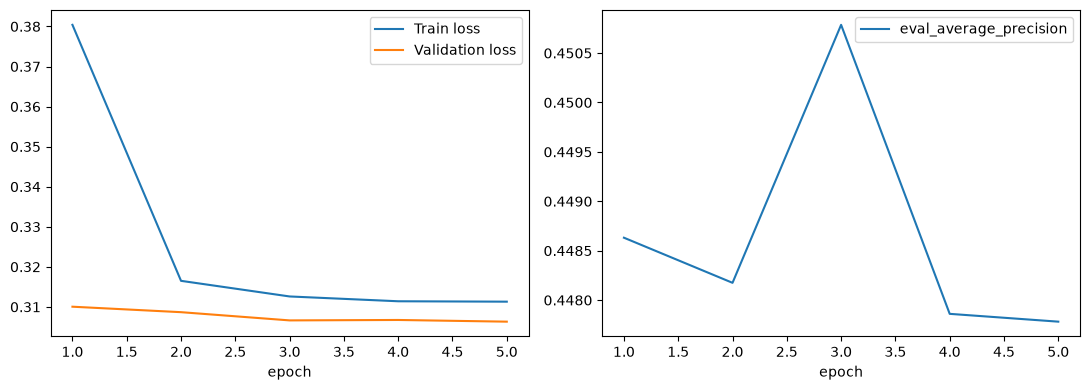

### failure_within_30d

,precision,recall,f1-score,support
0,0.873161,0.940437,0.905551,1830.000000
1,0.509009,0.311295,0.386325,363.000000
accuracy,0.836297,0.836297,0.836297,0.836297
macro avg,0.691085,0.625866,0.645938,2193.000000
weighted avg,0.812884,0.836297,0.819605,2193.000000


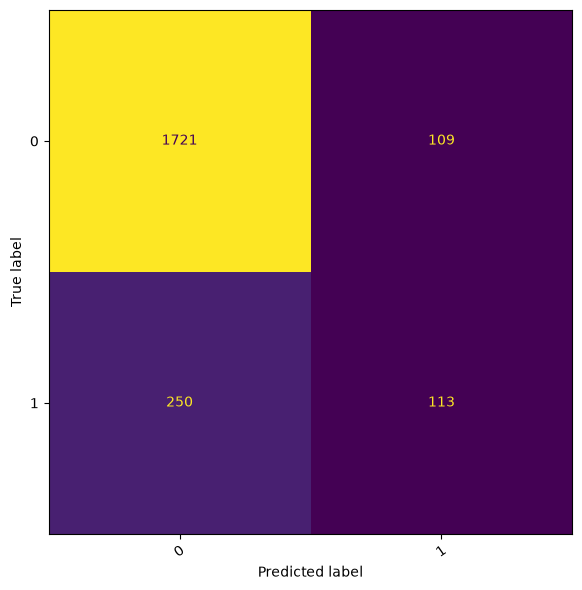

Ошибок validation: **359**.

,id,y_true,y_pred,probability_0,probability_1,operator_log,equipment,severity
2,14,0,1,0.435930,0.564070,"Слышен характерный шум, давление нестабильно, ...",PN-200,low
4,41,0,1,0.463996,0.536004,"Слышен характерный шум, давление нестабильно, ...",TR-90,medium
8,85,0,1,0.463283,0.536717,"Слышен характерный шум, давление нестабильно, ...",TR-90,medium
12,112,1,0,0.627769,0.372231,Оператор отмечает нарастающий гул в зоне подши...,CP-500,medium
16,125,1,0,0.899388,0.100612,Обнаружены следы утечки в зоне уплотнения и сн...,PN-300,medium
21,162,1,0,0.630489,0.369511,Зафиксирован устойчивый рост температуры корпу...,FV-40,high
30,201,0,1,0.453438,0.546562,"Слышен характерный шум, давление нестабильно, ...",PN-200,medium
33,215,1,0,0.605441,0.394559,Зафиксирован устойчивый рост температуры корпу...,TR-90,medium
34,228,1,0,0.633882,0.366118,Оператор отмечает нарастающий гул в зоне подши...,FV-40,medium
49,332,1,0,0.880940,0.119060,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,medium


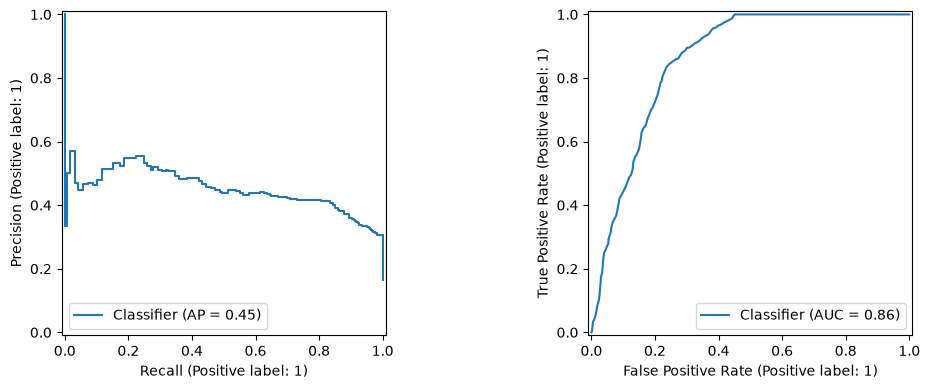

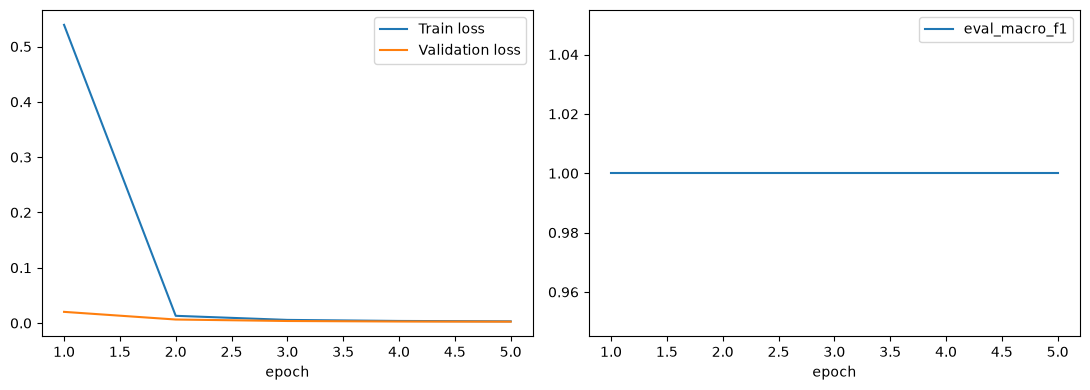

### fault_type

,precision,recall,f1-score,support
bearing_wear,1.0,1.0,1.0,255.0
cavitation,1.0,1.0,1.0,222.0
imbalance,1.0,1.0,1.0,232.0
normal,1.0,1.0,1.0,1005.0
overheat,1.0,1.0,1.0,252.0
seal_leak,1.0,1.0,1.0,227.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,2193.0
weighted avg,1.0,1.0,1.0,2193.0


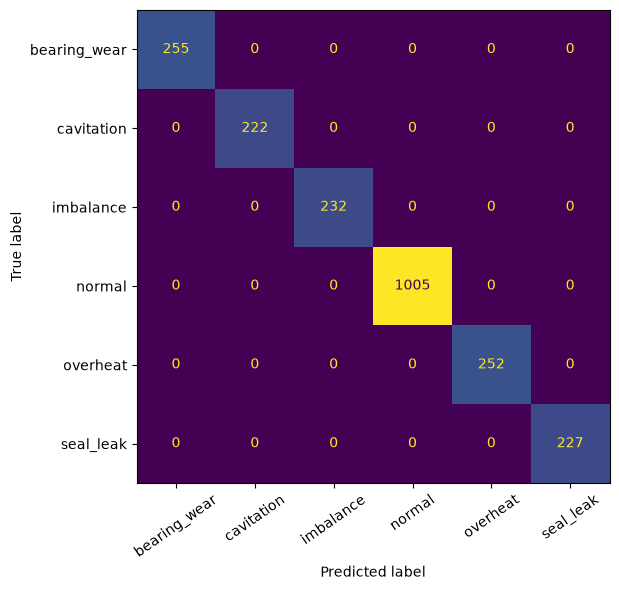

Ошибок validation: **0**.

,id,y_true,y_pred,probability_bearing_wear,probability_cavitation,probability_imbalance,probability_normal,probability_overheat,probability_seal_leak,operator_log,equipment,severity


In [8]:
for row in results:
    target = row["target"]
    classes = CONFIG["expected_classes"][target]
    directory = PROJECT_ROOT / row["run_path"]
    predictions = prediction_tables[(target, "validation")]
    history = json.loads((directory / "history.json").read_text())
    history_frame = pd.DataFrame(history)
    metric = "eval_" + CONFIG["targets"][target]
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    history_frame.dropna(subset=["loss"]).plot(
        x="epoch", y="loss", ax=axes[0], label="Train loss"
    )
    history_frame.dropna(subset=["eval_loss"]).plot(
        x="epoch", y="eval_loss", ax=axes[0], label="Validation loss"
    )
    history_frame.dropna(subset=[metric]).plot(
        x="epoch", y=metric, ax=axes[1], label=metric
    )
    figure.tight_layout()
    figure.savefig(directory / "learning_curves.png")
    plt.show()
    plt.close(figure)
    report = pd.DataFrame(classification_report(
        predictions.y_true, predictions.y_pred,
        labels=classes, output_dict=True, zero_division=0,
    )).T
    report.to_csv(directory / "classification_report.csv")
    display(Markdown(f"### {target}"))
    display(report)
    matrix = confusion_matrix(
        predictions.y_true, predictions.y_pred, labels=classes
    )
    pd.DataFrame(matrix, index=classes, columns=classes).to_csv(
        directory / "confusion_matrix.csv"
    )
    figure, axis = plt.subplots(figsize=(8, 6))
    ConfusionMatrixDisplay(matrix, display_labels=classes).plot(
        ax=axis, colorbar=False, xticks_rotation=35
    )
    figure.tight_layout()
    figure.savefig(directory / "confusion_matrix.png")
    plt.show()
    plt.close(figure)
    diagnosis = predictions.merge(
        validation[["id", "operator_log", "equipment", "severity"]],
        on="id", validate="one_to_one",
    )
    errors = diagnosis.loc[diagnosis.y_true.ne(diagnosis.y_pred)]
    errors.head(CONFIG["error_examples"]).to_csv(
        directory / "error_examples.csv", index=False
    )
    display(Markdown(f"Ошибок validation: **{len(errors)}**."))
    display(errors.head(CONFIG["error_examples"]))
    subgroups = []
    for grouping in ["equipment", "severity"]:
        for value, group in diagnosis.groupby(grouping):
            subgroups.append({
                "grouping": grouping, "value": value, "rows": len(group),
                **baseline.classification_metrics(group, classes, target),
            })
    pd.DataFrame(subgroups).to_csv(directory / "subgroups.csv", index=False)
    if target == "failure_within_30d":
        figure, axes = plt.subplots(1, 2, figsize=(11, 4))
        PrecisionRecallDisplay.from_predictions(
            predictions.y_true, predictions.probability_1, ax=axes[0]
        )
        RocCurveDisplay.from_predictions(
            predictions.y_true, predictions.probability_1, ax=axes[1]
        )
        figure.tight_layout()
        figure.savefig(directory / "pr_roc.png")
        plt.show()
        plt.close(figure)

## 8. F2-порог после выбора эпохи

Сохраняем исходные прогнозы при 0,5. Порог не меняет вероятности,
AP или ROC-AUC. Решение положительно при probability_1 >= threshold.
Файл decision_rule.json хранится рядом с моделью; from_pretrained сам
по себе этот порог не применяет. Для применения нужна та же явная проверка.
Дополнительные точки precision ≥ 70%/80% — только диагностика.

In [9]:
binary_target = "failure_within_30d"
binary_row = next(row for row in results if row["target"] == binary_target)
binary_directory = PROJECT_ROOT / binary_row["run_path"]
original = prediction_tables[(binary_target, "validation")]
best_threshold, curve = baseline.select_failure_threshold(
    original.y_true, original.probability_1, CONFIG["selection_decimals"]
)
np.testing.assert_array_equal(
    original.probability_1.ge(best_threshold["threshold"]),
    reloaded_predictions[binary_target].probability_1.ge(
        best_threshold["threshold"]
    ),
)
curve.to_csv(binary_directory / "threshold_curve.csv", index=False)
write_json(binary_directory / "model/decision_rule.json", {
    "positive_class": 1, "threshold": best_threshold["threshold"],
    "rule": "probability_1 >= threshold", "selection_split": "validation",
    "selection_metric": "f2", "refit": False,
})
threshold_metrics = []
for split in ["train", "validation"]:
    predictions = prediction_tables[(binary_target, split)].copy()
    predictions["y_pred"] = predictions.probability_1.ge(
        best_threshold["threshold"]
    ).astype(int)
    predictions.to_csv(
        binary_directory / f"{split}_predictions_f2.csv", index=False
    )
    before = baseline.classification_metrics(
        prediction_tables[(binary_target, split)], [0, 1], binary_target
    )
    after = baseline.classification_metrics(predictions, [0, 1], binary_target)
    assert before["average_precision"] == after["average_precision"]
    assert before["roc_auc"] == after["roc_auc"]
    for name, values in [("default_0.5", before), ("selected_f2", after)]:
        threshold_metrics.append({"split": split, "rule": name, **values})
    prediction_tables[(binary_target, split + "_f2")] = predictions
    if split == "validation":
        pd.DataFrame(confusion_matrix(
            predictions.y_true, predictions.y_pred, labels=[0, 1]
        ), index=[0, 1], columns=[0, 1]).to_csv(
            binary_directory / "confusion_matrix_f2.csv"
        )
pd.DataFrame(threshold_metrics).to_csv(
    binary_directory / "threshold_metrics.csv", index=False
)
operating_points = [
    baseline.precision_recall_operating_point(
        curve, floor, CONFIG["selection_decimals"]
    ) for floor in CONFIG["precision_floors"]
]
pd.DataFrame(operating_points).to_csv(
    binary_directory / "precision_operating_points.csv", index=False
)
display(pd.DataFrame(threshold_metrics))
display(pd.DataFrame(operating_points))
with mlflow.start_run(run_id=binary_row["run_id"]):
    mlflow.log_param("f2_threshold", best_threshold["threshold"])
    mlflow.log_metrics({
        "validation_f2_threshold_" + key: value
        for key, value in baseline.classification_metrics(
            prediction_tables[(binary_target, "validation_f2")],
            [0, 1], binary_target,
        ).items() if value is not None
    })

,split,rule,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision
0,train,default_0.5,0.835195,0.644789,0.309837,0.513564,0.307563,0.384723,0.334389,0.861027,0.467611
1,train,selected_f2,0.722008,0.662922,0.309837,0.366523,0.905322,0.521795,0.699628,0.861027,0.467611
2,validation,default_0.5,0.836297,0.645938,0.306624,0.509009,0.311295,0.386325,0.337515,0.858636,0.450304
3,validation,selected_f2,0.731874,0.669128,0.306624,0.371429,0.895317,0.525040,0.698324,0.858636,0.450304


,precision_floor,status,threshold,precision,recall,f1,f2,tp,fp,tn,fn
0,0.7,unattainable,None,None,None,None,None,None,None,None,None
1,0.8,unattainable,None,None,None,None,None,None,None,None,None


## 9. Парные групповые сравнения

Шесть сравнений AP/macro-F1: каждая цель против TF-IDF, числового CatBoost
и prior. Ещё три F2: выбранный порог против 0,5 и против сохранённых
F2-решений TF-IDF/CatBoost. В каждом — 2 000 повторов, группы eda_v1
переносятся целиком. Пороги фиксированы, повторного обучения нет.
Интервалы условны относительно выбора эпохи и порога на той же validation;
они могут быть оптимистичными и не заменяют итоговый test.

In [10]:
validation_groups = membership.loc[
    membership["split"].eq("validation"), ["id", "group_id"]
]
comparisons = []
for (name, target), reference in references.items():
    comparisons.append({
        "target": target, "reference": name,
        **paired_group_bootstrap(
            reference["predictions"],
            prediction_tables[(target, "validation")], validation_groups,
            CONFIG["expected_classes"][target], target, **CONFIG["bootstrap"],
        ),
    })
f2_references = {"default_0.5": original}
for name in ["tfidf", "catboost_numeric"]:
    f2_references[name] = pd.read_csv(
        references[(name, binary_target)]["directory"]
        / "validation_predictions_f2.csv",
        dtype={"id": "string"}, float_precision="round_trip",
    )
for name, predictions in f2_references.items():
    comparisons.append({
        "target": binary_target, "reference": name,
        **paired_group_bootstrap(
            predictions, prediction_tables[(binary_target, "validation_f2")],
            validation_groups, [0, 1], binary_target, metric="f2",
            **CONFIG["bootstrap"],
        ),
    })
assert len(comparisons) == 9
comparison_results = pd.DataFrame(comparisons)
comparison_results.to_csv(
    batch_directory / "paired_bootstrap.csv", index=False
)
display(comparison_results)

,target,reference,metric,reference_score,candidate_score,difference,lower_95,upper_95,groups,requested_repeats,valid_repeats,skipped_repeats,seed,direction
0,failure_within_30d,tfidf,average_precision,0.442193,0.450304,0.008111,-0.012195,0.028519,59,2000,2000,0,42,candidate - reference
1,fault_type,tfidf,macro_f1,1.000000,1.000000,0.000000,0.000000,0.000000,59,2000,2000,0,42,candidate - reference
2,failure_within_30d,catboost_numeric,average_precision,0.786742,0.450304,-0.336438,-0.375678,-0.290448,59,2000,2000,0,42,candidate - reference
3,fault_type,catboost_numeric,macro_f1,0.757161,1.000000,0.242839,0.222900,0.279652,59,2000,2000,0,42,candidate - reference
4,failure_within_30d,prior,average_precision,0.165527,0.450304,0.284778,0.209277,0.354029,59,2000,2000,0,42,candidate - reference
5,fault_type,prior,macro_f1,0.104753,1.000000,0.895247,0.873183,0.930498,59,2000,2000,0,42,candidate - reference
6,failure_within_30d,default_0.5,f2,0.337515,0.698324,0.360809,0.235830,0.507101,59,2000,2000,0,42,candidate - reference
7,failure_within_30d,tfidf,f2,0.694444,0.698324,0.003880,-0.007785,0.020473,59,2000,2000,0,42,candidate - reference
8,failure_within_30d,catboost_numeric,f2,0.827506,0.698324,-0.129182,-0.166528,-0.099154,59,2000,2000,0,42,candidate - reference


## 10. Завершение и проверяемая сводка

Успешный опыт — два обучения и две завершённые записи MLflow, сохранённые
модели/токенизатор, исходные прогнозы, порог, кривые и девять сравнений.
Результат сохраняется независимо от направления разности с контролями.
Здесь нет объединения признаков, поиска настроек или оценки test.

In [11]:
assert len(results) == CONFIG["expected_training_runs"]
assert data.file_sha256(membership_path) == CONFIG["membership_sha256"]
assert data.file_sha256(
    PROJECT_ROOT / dataset_config["dataset"]
) == dataset_config["sha256"]
for relative, checksum in reference_checksums.items():
    assert data.file_sha256(PROJECT_ROOT / relative) == checksum
for row in results:
    with mlflow.start_run(run_id=row["run_id"]):
        directory = PROJECT_ROOT / row["run_path"]
        for path in directory.iterdir():
            if path.is_file():
                mlflow.log_artifact(str(path))
        if row["target"] == binary_target:
            mlflow.log_artifact(str(directory / "model/decision_rule.json"))
    assert mlflow.get_run(row["run_id"]).info.status == "FINISHED"
manifest.update({
    "status": "completed",
    "finished_at_utc": datetime.now(timezone.utc).isoformat(),
    "selected_models": results, "bootstrap_comparisons": len(comparisons),
    "threshold": best_threshold, "test_evaluated": False,
})
write_json(batch_directory / "manifest.json", manifest)
summary = [
    "# RuBERT-tiny2: выполненный опыт B", "",
    "Два независимых обучения, один seed, пять эпох; вход operator_log.",
    "Test не оценивался. Число сравнений: 9.", "",
]
for row in results:
    metric = CONFIG["targets"][row["target"]]
    summary.append(
        f"- {row['target']}: {metric}={row[metric]:.6f}; "
        f"эпоха={row['best_epoch']}; fit={row['fit_seconds']:.2f} с."
    )
summary.extend([
    "", f"F2-порог: {best_threshold['threshold']!r}.", "",
    "Выбор эпохи и порога выполнен на одной validation; оценки условны.",
    "Шесть шаблонов ограничивают перенос на неизвестные формулировки.",
    "Бутстрэп не оценивает вариативность повторного обучения.",
])
(batch_directory / "summary.md").write_text(
    "\n".join(summary), encoding="utf-8"
)
logger.info("Завершено: %s", batch_directory)
display(Markdown("\n".join(summary)))

2026-10-18 14:24:24,835 Завершено: C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\artifacts\experiments\rubert_tiny2_20261018T111625_114468Z


# RuBERT-tiny2: выполненный опыт B

Два независимых обучения, один seed, пять эпох; вход operator_log.
Test не оценивался. Число сравнений: 9.

- failure_within_30d: average_precision=0.450304; эпоха=3.0; fit=199.48 с.
- fault_type: macro_f1=1.000000; эпоха=1.0; fit=201.27 с.

F2-порог: 0.13099803786189806.

Выбор эпохи и порога выполнен на одной validation; оценки условны.
Шесть шаблонов ограничивают перенос на неизвестные формулировки.
Бутстрэп не оценивает вариативность повторного обучения.